<div style="background:linear-gradient(90deg,#1e3a8a,#2563eb);padding:22px 26px;border-radius:12px;color:white">
<h1 style="margin:0;color:white">Bank Customer Churn Prediction</h1>
<div style="font-size:16px;margin-top:6px">Artificial Neural Network (ANN / DNN) with Analytics Dashboard and Prediction UI</div>
<div style="font-size:13px;margin-top:10px;opacity:.9">Prepared by: Muhammad Talha Tahir

 &nbsp;|&nbsp; Reg. No: fa23-bbd-107 &nbsp;|&nbsp; BS Business Data Analytics, COMSATS University Islamabad</div>
</div>

### Table of contents
| # | Section | # | Section |
|---|---|---|---|
| 1 | [Problem Definition](#s1) | 9 | [Model Architecture and Compilation](#s9) |
| 2 | [Dataset Description and Source](#s2) | 10 | [Model Training](#s10) |
| 3 | [Proposed Solution](#s3) | 11 | [Evaluation](#s11) |
| 4 | [Load Data and Quality Checks](#s4) | 12 | [Feature Importance](#s12) |
| 5 | [Exploratory Data Analysis](#s5) | 13 | [Predictions for New Customers](#s13) |
| 6 | [Data Preprocessing](#s6) | 14 | [Dashboard](#s14) |
| 7 | [Train / Validation / Test Split](#s7) | 15 | [User Interface](#s15) |
| 8 | [Baseline Model](#s8) | 16 | [Conclusion and Recommendations](#s16) |

In [1]:
# Setup: libraries, reproducibility and a consistent visual theme
import os, json, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.gridspec import GridSpec
from IPython.display import display, HTML, Markdown

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, precision_recall_curve,
                             average_precision_score)

SEED = 42
keras.utils.set_random_seed(SEED)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
C_STAY, C_CHURN, C_NEUTRAL = '#2563eb', '#dc2626', '#64748b'
pd.options.display.float_format = '{:,.2f}'.format
print('TensorFlow', tf.__version__, '| pandas', pd.__version__)

I0000 00:00:1793032514.902938      88 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793032543.806181      88 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | pandas 3.0.2


<a id="s1"></a>
## 1. Problem Definition
**Business context.** Customer churn (attrition) means a customer closes their relationship with the bank. Winning a new customer costs far more than keeping an existing one, so identifying customers who are *about to leave* lets the bank act early with retention offers.

**Business question.** *Which customers are most likely to leave the bank, and what characterises them?*

**Analytical task.** Binary classification: predict `Exited` (1 = churned, 0 = stayed) from demographic and account information.

**Success criteria.**
- A model that clearly beats a simple benchmark (Logistic Regression) on ROC-AUC and F1-score.
- Because only about 1 in 5 customers churns, performance is judged on **precision, recall, F1 and ROC-AUC**, not on accuracy alone.
- Clear, usable outputs for the business: a risk score per customer, key churn drivers, a dashboard and a simple prediction tool.

<a id="s2"></a>
## 2. Dataset Description and Source
- **Dataset:** Churn Modelling, a public bank customer dataset (file `Churn_Modelling.csv`).
- **Source link:** https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling
- **Size:** 10,000 customers (one row each) and 14 columns.
- **Target:** `Exited`.

| Column | Type | Description | Used in model |
|---|---|---|---|
| RowNumber | ID | Row index | No (identifier) |
| CustomerId | ID | Unique customer ID | No (identifier) |
| Surname | Text | Customer surname | No (no predictive meaning, privacy risk) |
| CreditScore | Numeric | Credit score (300 to 850) | Yes |
| Geography | Categorical | France / Germany / Spain | Yes (one-hot) |
| Gender | Categorical | Female / Male | Yes (binary) |
| Age | Numeric | Age in years | Yes |
| Tenure | Numeric | Years with the bank (0 to 10) | Yes |
| Balance | Numeric | Account balance | Yes |
| NumOfProducts | Numeric | Number of bank products held | Yes |
| HasCrCard | Binary | Has a credit card | Yes |
| IsActiveMember | Binary | Active member | Yes |
| EstimatedSalary | Numeric | Estimated annual salary | Yes |
| **Exited** | **Binary** | **1 = churned, 0 = stayed (target)** | **Target** |

<a id="s3"></a>
## 3. Proposed Solution
We build a feed-forward **neural network (ANN / DNN)** that outputs the probability that a customer will churn, and benchmark it against Logistic Regression.

| Phase | What we do | Section |
|---|---|---|
| Understand | Load data, check data quality, explore patterns | 4, 5 |
| Prepare | Remove irrelevant columns, encode, scale, split into train / validation / test | 6, 7 |
| Model | Baseline model, then ANN (input, hidden and output layers), compile and train | 8, 9, 10 |
| Evaluate | Accuracy, precision, recall, F1, ROC-AUC, confusion matrix, threshold tuning, feature importance | 11, 12 |
| Deploy / communicate | Predict for new customers, dashboard, interactive UI, recommendations | 13, 14, 15, 16 |

**Design choices:** a separate *validation set* is used for early stopping and for choosing the decision threshold, so the *test set* stays untouched until the final evaluation. Class weights handle the class imbalance.

<a id="s4"></a>
## 4. Load Data and Quality Checks

In [2]:
DATA_PATH = 'Churn_Modelling.csv'
df = pd.read_csv(DATA_PATH)
print(f'Rows: {df.shape[0]:,}   Columns: {df.shape[1]}')
df.head()

Rows: 10,000   Columns: 14


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0


In [3]:
# Column types, missing values and unique counts
schema = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isnull().sum(), 'unique values': df.nunique()})
display(schema)

checks = pd.DataFrame({
    'Check': ['Missing values (total)', 'Duplicate rows', 'Duplicate CustomerId', 'CreditScore range',
              'Age range', 'Tenure range', 'Customers with zero balance', 'Churn rate (target)'],
    'Result': [int(df.isnull().sum().sum()), int(df.duplicated().sum()), int(df['CustomerId'].duplicated().sum()),
               f"{df.CreditScore.min()} to {df.CreditScore.max()}", f"{df.Age.min()} to {df.Age.max()}",
               f"{df.Tenure.min()} to {df.Tenure.max()}", f"{(df.Balance == 0).mean():.1%}", f"{df.Exited.mean():.1%}"],
    'Verdict': ['OK', 'OK', 'OK', 'Valid', 'Valid', 'Valid', 'Genuine (many customers hold no balance)', 'Imbalanced: handled with class weights']})
display(checks.style.hide(axis='index'))

,dtype,missing,unique values
RowNumber,int64,0,10000
CustomerId,int64,0,10000
Surname,str,0,2932
CreditScore,int64,0,460
Geography,str,0,3
Gender,str,0,2
Age,int64,0,70
Tenure,int64,0,11
Balance,float64,0,6382
NumOfProducts,int64,0,4


Check,Result,Verdict
Missing values (total),0,OK
Duplicate rows,0,OK
Duplicate CustomerId,0,OK
CreditScore range,350 to 850,Valid
Age range,18 to 92,Valid
Tenure range,0 to 10,Valid
Customers with zero balance,36.2%,Genuine (many customers hold no balance)
Churn rate (target),20.4%,Imbalanced: handled with class weights


**Data quality verdict:** the data is clean (no missing values, no duplicates, all ranges are realistic). The only point needing care is the **class imbalance** (about 20% churners), which is addressed later with class weights and a tuned decision threshold.

<a id="s5"></a>
## 5. Exploratory Data Analysis (EDA)
### 5.1 Target distribution

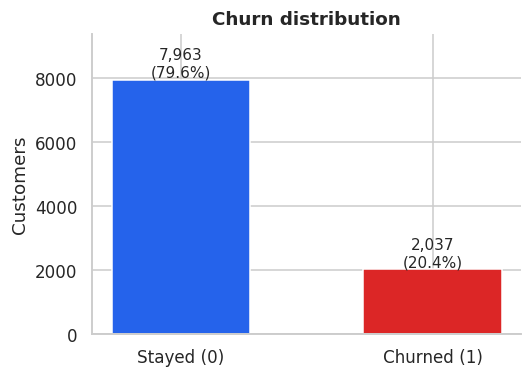

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.6))
cnt = df['Exited'].value_counts().sort_index()
bars = ax.bar(['Stayed (0)', 'Churned (1)'], cnt.values, color=[C_STAY, C_CHURN], width=.55)
for b, v in zip(bars, cnt.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 80, f'{v:,}\n({v / len(df):.1%})', ha='center', fontsize=10)
ax.set_ylim(0, cnt.max() * 1.18); ax.set_ylabel('Customers'); ax.set_title('Churn distribution')
plt.tight_layout(); plt.show()

### 5.2 Numeric features vs churn

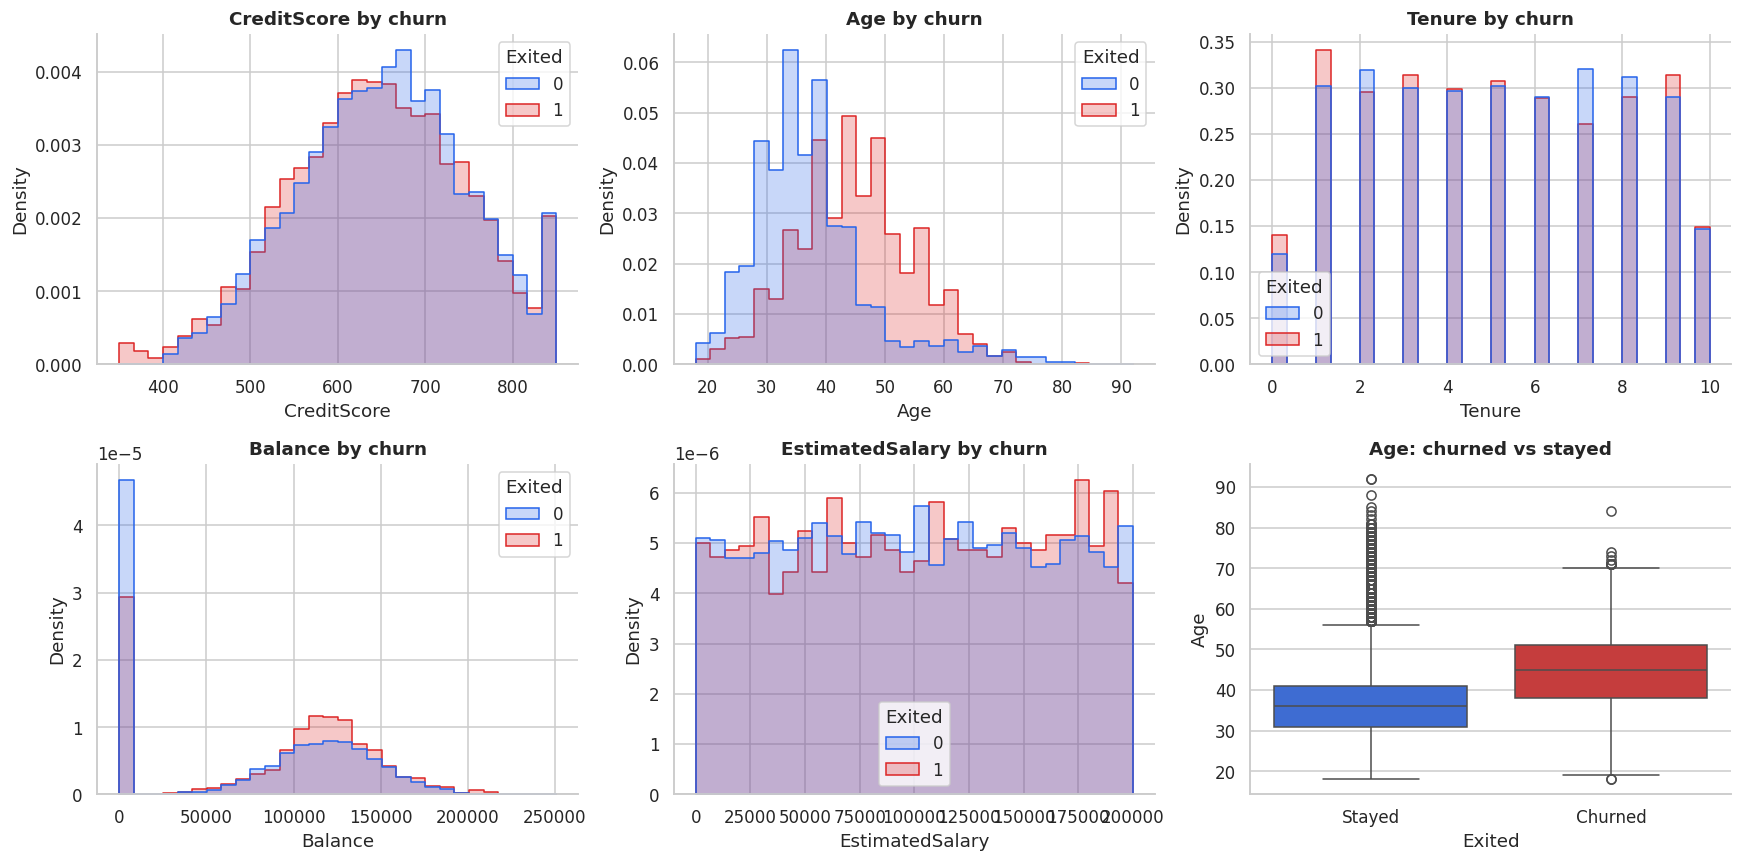

In [5]:
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=c, hue='Exited', bins=30, stat='density', common_norm=False,
                 palette=[C_STAY, C_CHURN], element='step', ax=ax)
    ax.set_title(f'{c} by churn')
sns.boxplot(data=df, x='Exited', y='Age', palette=[C_STAY, C_CHURN], ax=axes[1, 2])
axes[1, 2].set_title('Age: churned vs stayed'); axes[1, 2].set_xticklabels(['Stayed', 'Churned'])
plt.tight_layout(); plt.show()

### 5.3 Categorical features vs churn rate

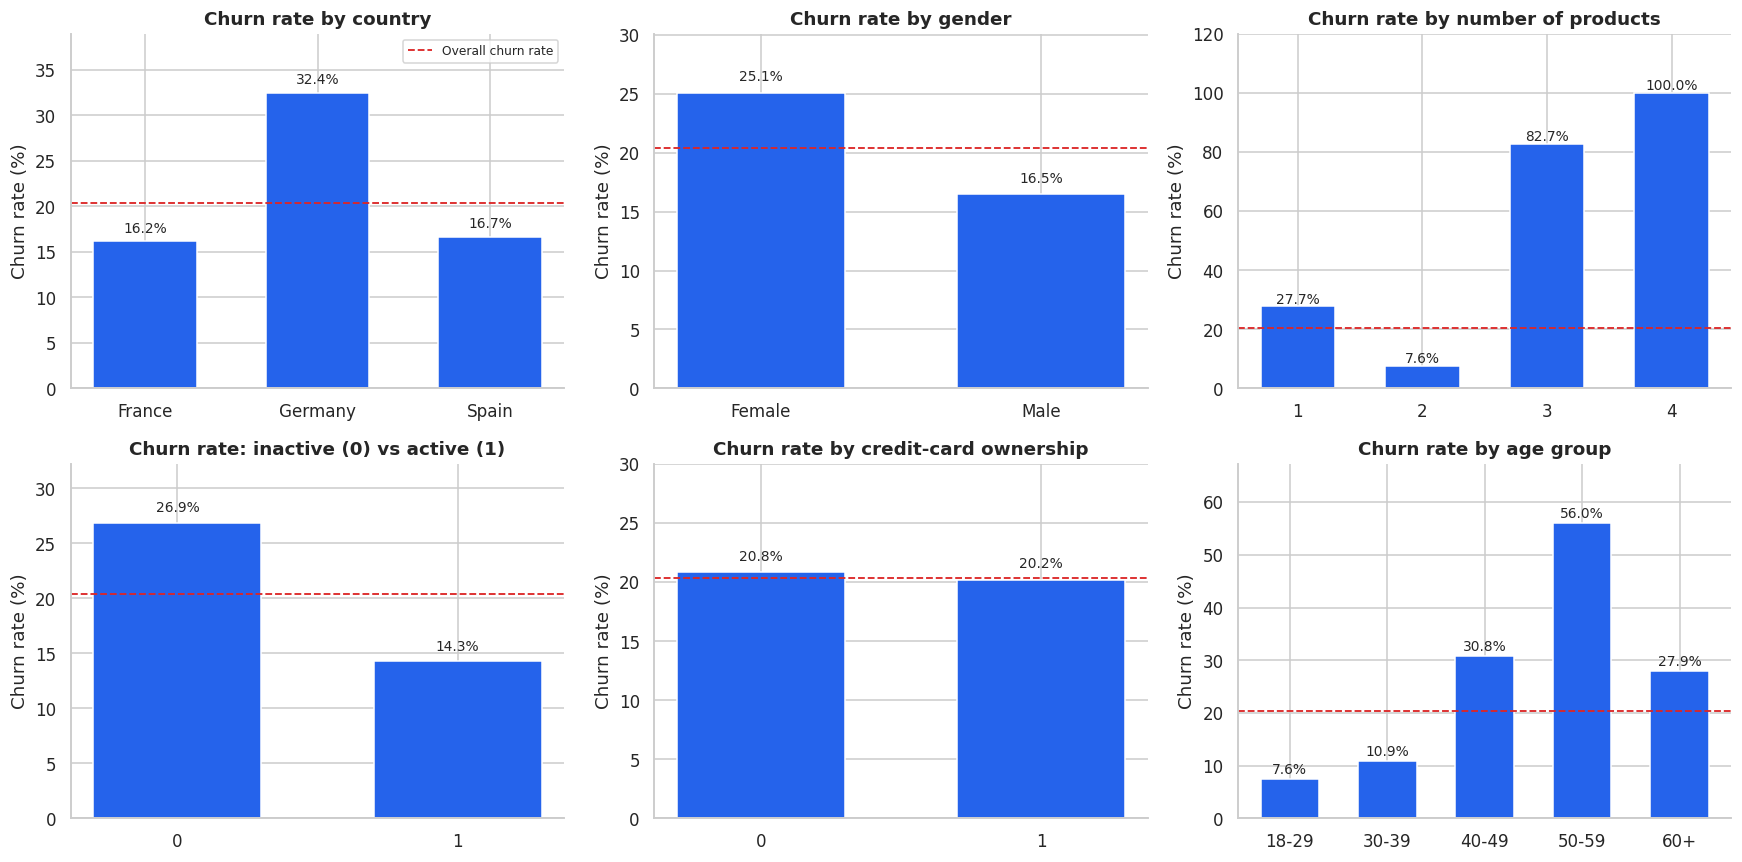

In [6]:
df['AgeGroup'] = pd.cut(df['Age'], [17, 29, 39, 49, 59, 100], labels=['18-29', '30-39', '40-49', '50-59', '60+'])

def rate_bar(ax, col, title, order=None):
    r = df.groupby(col, observed=True)['Exited'].mean().mul(100)
    if order is not None: r = r.reindex(order)
    bars = ax.bar(r.index.astype(str), r.values, color=C_STAY, width=.6)
    ax.axhline(df.Exited.mean() * 100, color=C_CHURN, ls='--', lw=1.2, label='Overall churn rate')
    for b, v in zip(bars, r.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.1f}%', ha='center', fontsize=9)
    ax.set_title(title); ax.set_ylabel('Churn rate (%)'); ax.set_xlabel(''); ax.set_ylim(0, max(r.max() * 1.2, 30))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
rate_bar(axes[0, 0], 'Geography', 'Churn rate by country')
rate_bar(axes[0, 1], 'Gender', 'Churn rate by gender')
rate_bar(axes[0, 2], 'NumOfProducts', 'Churn rate by number of products')
rate_bar(axes[1, 0], 'IsActiveMember', 'Churn rate: inactive (0) vs active (1)')
rate_bar(axes[1, 1], 'HasCrCard', 'Churn rate by credit-card ownership')
rate_bar(axes[1, 2], 'AgeGroup', 'Churn rate by age group')
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.4 Correlation between numeric variables

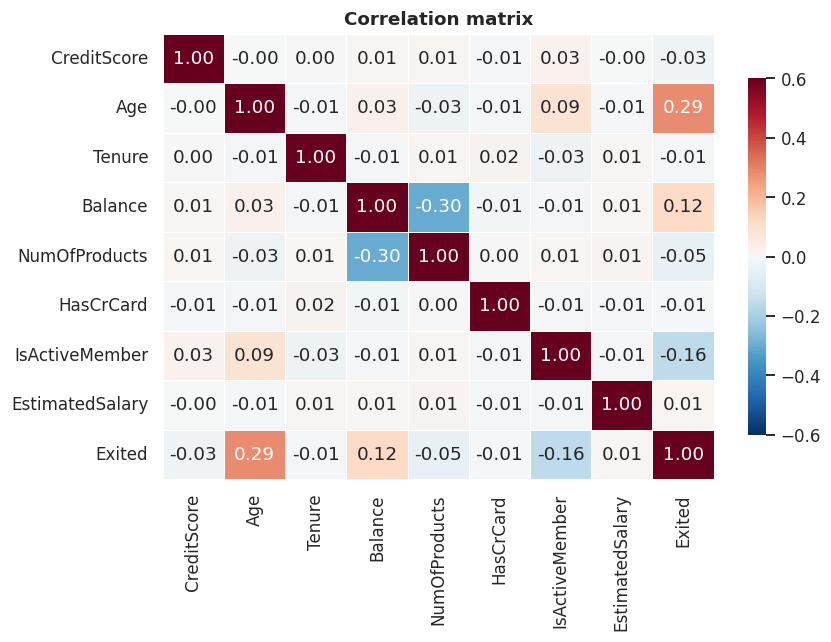

In [7]:
corr_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-.6, vmax=.6,
            linewidths=.5, cbar_kws={'shrink': .8}, ax=ax)
ax.set_title('Correlation matrix'); plt.tight_layout(); plt.show()

### 5.5 Key findings from EDA

In [8]:
def rate(mask): return df.loc[mask, 'Exited'].mean()
ins = {
    'overall': df.Exited.mean(),
    'age40': rate(df.Age >= 40), 'age_u40': rate(df.Age < 40),
    'inactive': rate(df.IsActiveMember == 0), 'active': rate(df.IsActiveMember == 1),
    'germany': rate(df.Geography == 'Germany'), 'france': rate(df.Geography == 'France'), 'spain': rate(df.Geography == 'Spain'),
    'p1': rate(df.NumOfProducts == 1), 'p2': rate(df.NumOfProducts == 2), 'p34': rate(df.NumOfProducts >= 3),
    'female': rate(df.Gender == 'Female'), 'male': rate(df.Gender == 'Male')}
display(Markdown(f"""| Finding | Evidence |
|---|---|
| **Age is the strongest signal** | Customers aged 40+ churn at **{ins['age40']:.1%}** vs **{ins['age_u40']:.1%}** for those under 40 |
| **Inactive members leave more** | Inactive: **{ins['inactive']:.1%}** vs active: **{ins['active']:.1%}** |
| **Germany is a hotspot** | Germany **{ins['germany']:.1%}**, Spain {ins['spain']:.1%}, France {ins['france']:.1%} |
| **Product count is non-linear** | 1 product {ins['p1']:.1%}, 2 products **{ins['p2']:.1%}** (lowest), 3 or 4 products **{ins['p34']:.1%}** |
| **Women churn slightly more** | Female {ins['female']:.1%} vs male {ins['male']:.1%} |
| **Salary and credit score matter little** | Their distributions are almost identical for churners and stayers |"""))

| Finding | Evidence |
|---|---|
| **Age is the strongest signal** | Customers aged 40+ churn at **35.9%** vs **10.0%** for those under 40 |
| **Inactive members leave more** | Inactive: **26.9%** vs active: **14.3%** |
| **Germany is a hotspot** | Germany **32.4%**, Spain 16.7%, France 16.2% |
| **Product count is non-linear** | 1 product 27.7%, 2 products **7.6%** (lowest), 3 or 4 products **85.9%** |
| **Women churn slightly more** | Female 25.1% vs male 16.5% |
| **Salary and credit score matter little** | Their distributions are almost identical for churners and stayers |

<a id="s6"></a>
## 6. Data Preprocessing
| Step | Action | Reason |
|---|---|---|
| 1 | Drop `RowNumber`, `CustomerId`, `Surname` | Identifiers carry no predictive information |
| 2 | Encode `Gender` as 0 / 1 | Neural networks need numeric inputs |
| 3 | One-hot encode `Geography` (drop one level) | No natural order between countries; dropping one level avoids redundancy |
| 4 | No missing-value treatment or outlier removal | No missing values; extreme ages are genuine customers |
| 5 | Standardise all features (after splitting) | Features have very different scales (e.g. Balance vs Tenure); scaling speeds up and stabilises training |

In [9]:
data = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'AgeGroup']).copy()
data['Gender'] = data['Gender'].map({'Female': 0, 'Male': 1})
data = pd.get_dummies(data, columns=['Geography'], drop_first=True, dtype=int)

X = data.drop(columns=['Exited'])
y = data['Exited']
feature_names = list(X.columns)
print(f'{len(feature_names)} model features:', feature_names)
X.head()

11 model features: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain']


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,"101,348.88",0,0
1,608,0,41,1,"83,807.86",1,0,1,"112,542.58",0,1
2,502,0,42,8,"159,660.80",3,1,0,"113,931.57",0,0
3,699,0,39,1,0.00,2,0,0,"93,826.63",0,0
4,850,0,43,2,"125,510.82",1,1,1,"79,084.10",0,1


<a id="s7"></a>
## 7. Train / Validation / Test Split
The data is split **stratified** (same churn rate in every part) into **64% train / 16% validation / 20% test**.
- *Train*: the model learns from it.
- *Validation*: used for early stopping and to choose the decision threshold.
- *Test*: used once, at the end, for an unbiased performance estimate.

The scaler is fitted on the training set only, to prevent data leakage.

In [10]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.20, stratify=y_temp, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(a) for a in (X_train, X_val, X_test))

split_summary = pd.DataFrame({'Customers': [len(y_train), len(y_val), len(y_test)],
                              'Churn rate': [y_train.mean(), y_val.mean(), y_test.mean()]},
                             index=['Train', 'Validation', 'Test'])
split_summary['Churn rate'] = split_summary['Churn rate'].map('{:.1%}'.format)
split_summary['Customers'] = split_summary['Customers'].map('{:,}'.format)
display(split_summary)

,Customers,Churn rate
Train,"6,400",20.4%
Validation,"1,600",20.4%
Test,"2,000",20.3%


<a id="s8"></a>
## 8. Baseline Model (Logistic Regression)
Before building the neural network we fit a simple, interpretable benchmark. The ANN must beat it to justify its extra complexity.

In [11]:
def evaluate(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred), 'F1-score': f1_score(y_true, pred), 'ROC-AUC': roc_auc_score(y_true, prob)}

lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED).fit(X_train_s, y_train)
p_lr_test = lr.predict_proba(X_test_s)[:, 1]
res_lr = evaluate(y_test, p_lr_test)
print('Baseline (Logistic Regression, class-balanced) on the test set:')
pd.Series(res_lr).to_frame('Score').T

Baseline (Logistic Regression, class-balanced) on the test set:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Score,0.71,0.38,0.71,0.50,0.78


<a id="s9"></a>
## 9. Model Architecture and Compilation
| Layer | Units | Activation | Purpose |
|---|---|---|---|
| Input | 11 | none | One neuron per feature |
| Hidden 1 (Dense) | 32 | ReLU | Learns non-linear feature combinations |
| Dropout | rate 0.3 | none | Randomly switches off neurons to reduce overfitting |
| Hidden 2 (Dense) | 16 | ReLU | Learns higher-level patterns |
| Dropout | rate 0.2 | none | Further regularisation |
| Output (Dense) | 1 | Sigmoid | Outputs churn probability between 0 and 1 |

**Compilation:** *Adam* optimiser (adaptive learning rate), *binary cross-entropy* loss (standard for two-class problems), and accuracy plus AUC as monitoring metrics. **Class weights** make errors on the minority (churn) class count more, so the model does not simply predict "stayed" for everyone.

In [12]:
model = keras.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
], name='churn_ann')

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy', keras.metrics.AUC(name='auc')])
model.summary()

n0, n1 = np.bincount(y_train)
class_weight = {0: len(y_train) / (2 * n0), 1: len(y_train) / (2 * n1)}
print('Class weights:', {k: round(v, 2) for k, v in class_weight.items()})

Model: "churn_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

Class weights: {0: np.float64(0.63), 1: np.float64(2.45)}


<a id="s10"></a>
## 10. Model Training
Training uses mini-batches of 32, up to 150 epochs, with **early stopping** on validation loss (best weights are restored) and a **learning-rate reduction** when progress stalls.

In [13]:
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
             keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5)]

history = model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                    epochs=150, batch_size=32, class_weight=class_weight, callbacks=callbacks, verbose=0)
h = history.history
best_ep = int(np.argmin(h['val_loss'])) + 1
print(f'Training stopped after {len(h["loss"])} epochs; best epoch = {best_ep}')
print(f'Train loss {h["loss"][best_ep-1]:.3f} | Val loss {h["val_loss"][best_ep-1]:.3f} | Val AUC {h["val_auc"][best_ep-1]:.3f}')

Training stopped after 34 epochs; best epoch = 19
Train loss 0.493 | Val loss 0.459 | Val AUC 0.852


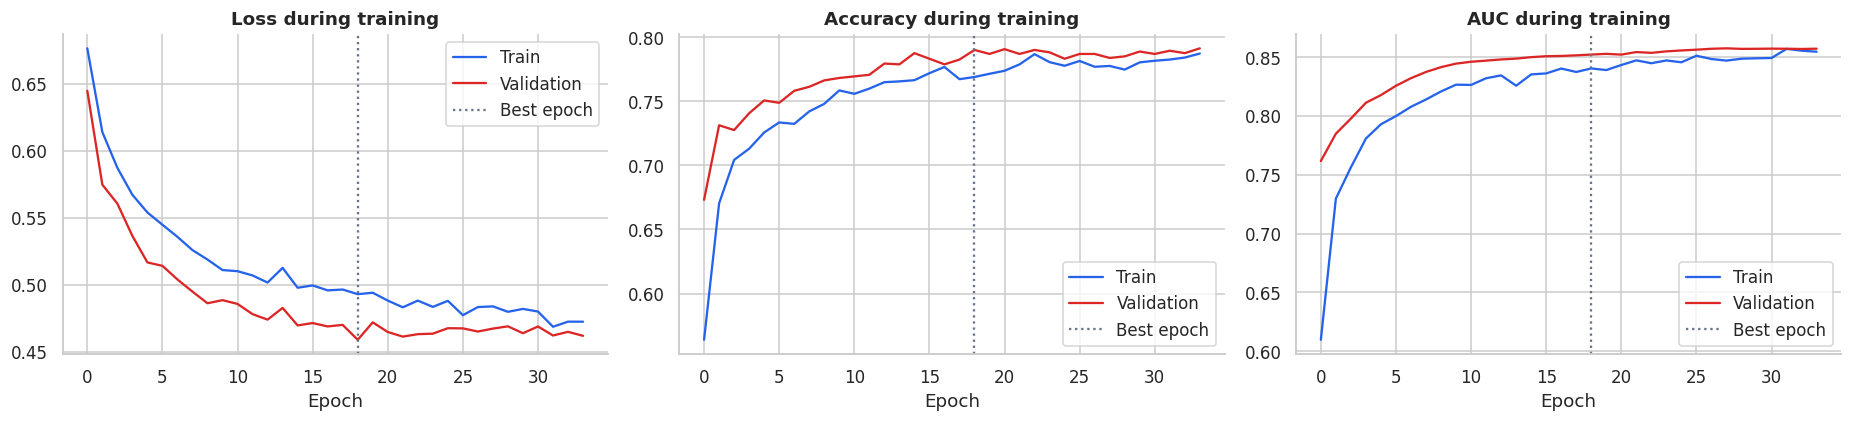

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, k, t in zip(ax, ['loss', 'accuracy', 'auc'], ['Loss', 'Accuracy', 'AUC']):
    a.plot(h[k], label='Train', color=C_STAY); a.plot(h['val_' + k], label='Validation', color=C_CHURN)
    a.axvline(best_ep - 1, color=C_NEUTRAL, ls=':', label='Best epoch')
    a.set_title(f'{t} during training'); a.set_xlabel('Epoch'); a.legend()
plt.tight_layout(); plt.show()

**Reading the curves:** training and validation curves move together and flatten near the best epoch, so the model learns the real pattern without memorising the training data (no serious overfitting).

<a id="s11"></a>
## 11. Evaluation
### 11.1 Choosing the decision threshold (on the validation set)
A neural network outputs a probability. The default cut-off of 0.5 is not necessarily best when churners are rare, so we pick the threshold that maximises F1-score **on the validation set** (never on the test set).

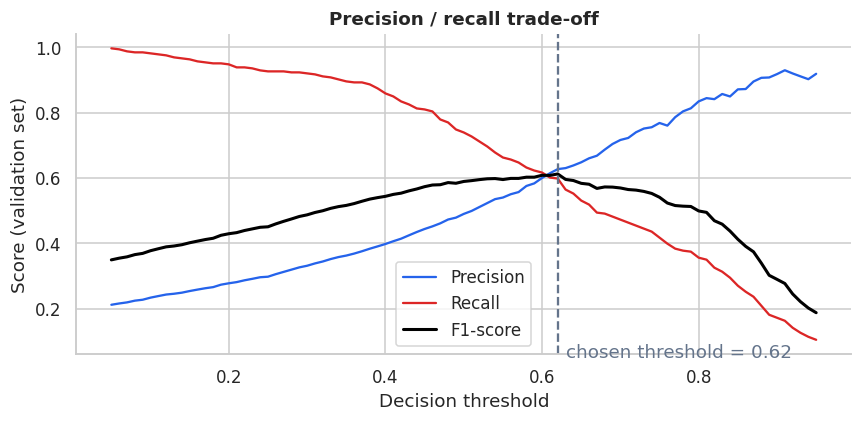

Selected threshold: 0.62


In [15]:
p_val  = model.predict(X_val_s,  verbose=0).ravel()
p_test = model.predict(X_test_s, verbose=0).ravel()

grid = np.arange(0.05, 0.96, 0.01)
f1s = [f1_score(y_val, (p_val >= t).astype(int)) for t in grid]
pre = [precision_score(y_val, (p_val >= t).astype(int), zero_division=0) for t in grid]
rec = [recall_score(y_val, (p_val >= t).astype(int)) for t in grid]
THR = float(grid[int(np.argmax(f1s))])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, pre, label='Precision', color=C_STAY); ax.plot(grid, rec, label='Recall', color=C_CHURN)
ax.plot(grid, f1s, label='F1-score', color='black', lw=2)
ax.axvline(THR, color=C_NEUTRAL, ls='--'); ax.text(THR + .01, .05, f'chosen threshold = {THR:.2f}', color=C_NEUTRAL)
ax.set_xlabel('Decision threshold'); ax.set_ylabel('Score (validation set)'); ax.set_title('Precision / recall trade-off'); ax.legend()
plt.tight_layout(); plt.show()
print(f'Selected threshold: {THR:.2f}')

### 11.2 Test-set performance and comparison with the baseline

In [16]:
res_ann_50  = evaluate(y_test, p_test, 0.5)
res_ann_thr = evaluate(y_test, p_test, THR)
comparison = pd.DataFrame({'Logistic Regression (baseline)': res_lr,
                           'ANN (threshold 0.50)': res_ann_50,
                           f'ANN (tuned threshold {THR:.2f})': res_ann_thr}).T
display(comparison.style.format('{:.3f}').highlight_max(color='#bbf7d0').set_caption('Test-set results (best value per metric highlighted)'))

y_pred = (p_test >= THR).astype(int)
acc, prec, rec_, f1, auc = (res_ann_thr[k] for k in ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'])
print('\nClassification report: final ANN at the tuned threshold')
print(classification_report(y_test, y_pred, target_names=['Stayed', 'Churned'], digits=3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression (baseline),0.710,0.384,0.705,0.497,0.778
ANN (threshold 0.50),0.787,0.486,0.767,0.595,0.856
ANN (tuned threshold 0.62),0.843,0.613,0.612,0.613,0.856



Classification report: final ANN at the tuned threshold
              precision    recall  f1-score   support

      Stayed      0.901     0.901     0.901      1593
     Churned      0.613     0.612     0.613       407

    accuracy                          0.843      2000
   macro avg      0.757     0.757     0.757      2000
weighted avg      0.842     0.843     0.842      2000



### 11.3 Confusion matrices, ROC and precision-recall curves

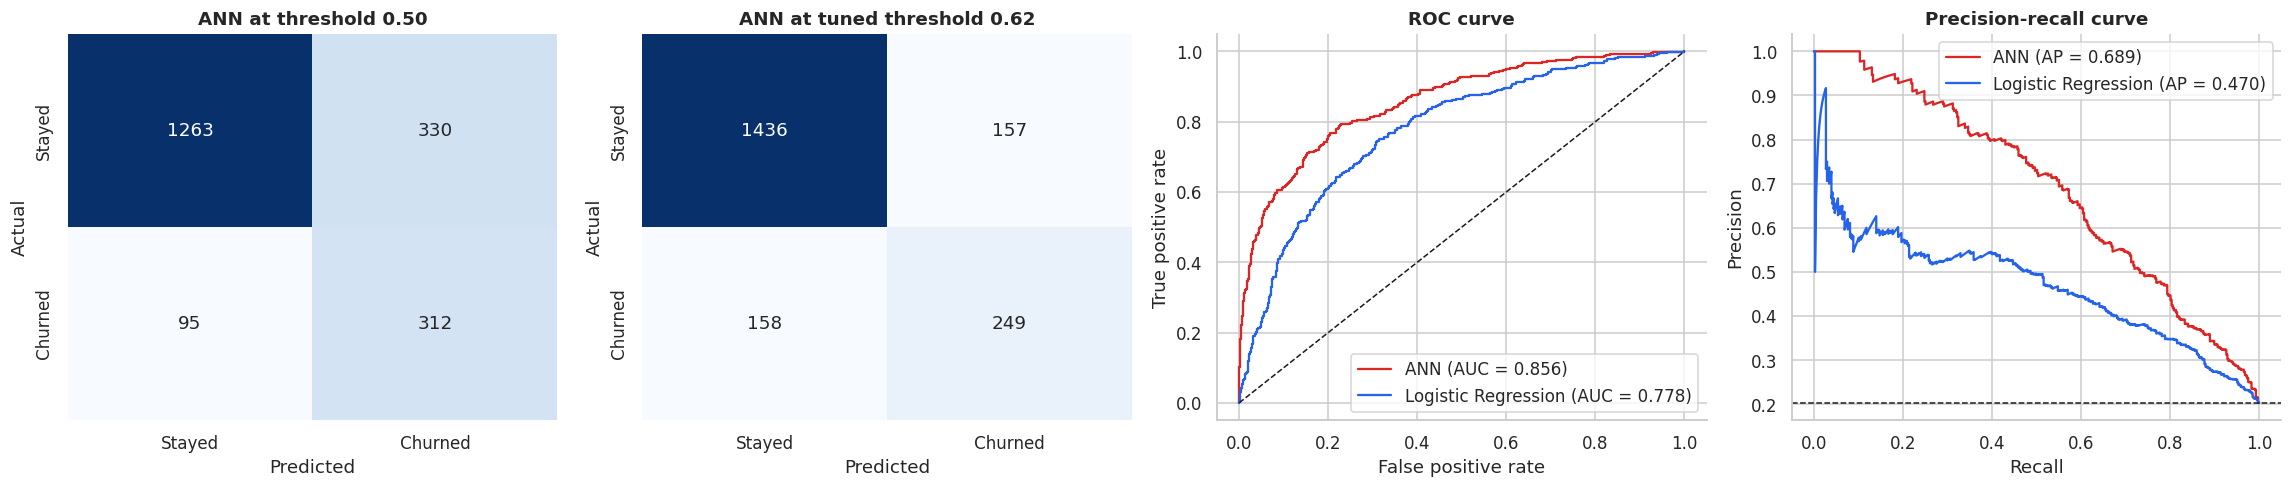

In [17]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.6))
for a, thr, t in zip(ax[:2], [0.5, THR], ['ANN at threshold 0.50', f'ANN at tuned threshold {THR:.2f}']):
    cmx = confusion_matrix(y_test, (p_test >= thr).astype(int))
    sns.heatmap(cmx, annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
    a.set_title(t); a.set_xlabel('Predicted'); a.set_ylabel('Actual')

for name, p, col in [('ANN', p_test, C_CHURN), ('Logistic Regression', p_lr_test, C_STAY)]:
    fpr, tpr, _ = roc_curve(y_test, p); ax[2].plot(fpr, tpr, color=col, label=f'{name} (AUC = {roc_auc_score(y_test, p):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, p); ax[3].plot(rc, pr, color=col, label=f'{name} (AP = {average_precision_score(y_test, p):.3f})')
ax[2].plot([0, 1], [0, 1], 'k--', lw=1); ax[2].set_title('ROC curve'); ax[2].set_xlabel('False positive rate'); ax[2].set_ylabel('True positive rate'); ax[2].legend()
ax[3].axhline(y_test.mean(), color='k', ls='--', lw=1); ax[3].set_title('Precision-recall curve'); ax[3].set_xlabel('Recall'); ax[3].set_ylabel('Precision'); ax[3].legend()
plt.tight_layout(); plt.show()
cm = confusion_matrix(y_test, y_pred)

In [18]:
tn, fp, fn, tp = cm.ravel()
display(Markdown(f"""### 11.4 Interpretation
- **ANN vs baseline:** the ANN reaches ROC-AUC **{auc:.3f}** (baseline {res_lr['ROC-AUC']:.3f}) and F1 **{f1:.3f}** (baseline {res_lr['F1-score']:.3f}).
- **Effect of threshold tuning:** moving the threshold from 0.50 to {THR:.2f} changes recall from {res_ann_50['Recall']:.1%} to **{rec_:.1%}** and precision from {res_ann_50['Precision']:.1%} to **{prec:.1%}**.
- **Final confusion matrix:** {tp:,} churners caught, {fn:,} churners missed, {fp:,} loyal customers flagged by mistake, {tn:,} loyal customers correctly left alone.
- **Business meaning:** of every 100 customers the model flags as churners, about **{prec*100:.0f}** really are; and it finds about **{rec_*100:.0f}%** of all customers who actually leave.
- **Why not just accuracy?** A model that always says "stayed" would already be about {1 - y_test.mean():.0%} accurate while catching no churners at all."""))

### 11.4 Interpretation
- **ANN vs baseline:** the ANN reaches ROC-AUC **0.856** (baseline 0.778) and F1 **0.613** (baseline 0.497).
- **Effect of threshold tuning:** moving the threshold from 0.50 to 0.62 changes recall from 76.7% to **61.2%** and precision from 48.6% to **61.3%**.
- **Final confusion matrix:** 249 churners caught, 158 churners missed, 157 loyal customers flagged by mistake, 1,436 loyal customers correctly left alone.
- **Business meaning:** of every 100 customers the model flags as churners, about **61** really are; and it finds about **61%** of all customers who actually leave.
- **Why not just accuracy?** A model that always says "stayed" would already be about 80% accurate while catching no churners at all.

<a id="s12"></a>
## 12. Feature Importance (what drives churn?)
**Permutation importance:** shuffle one feature at a time on the test set and measure how much the ROC-AUC drops. A bigger drop means the model relies more on that feature.

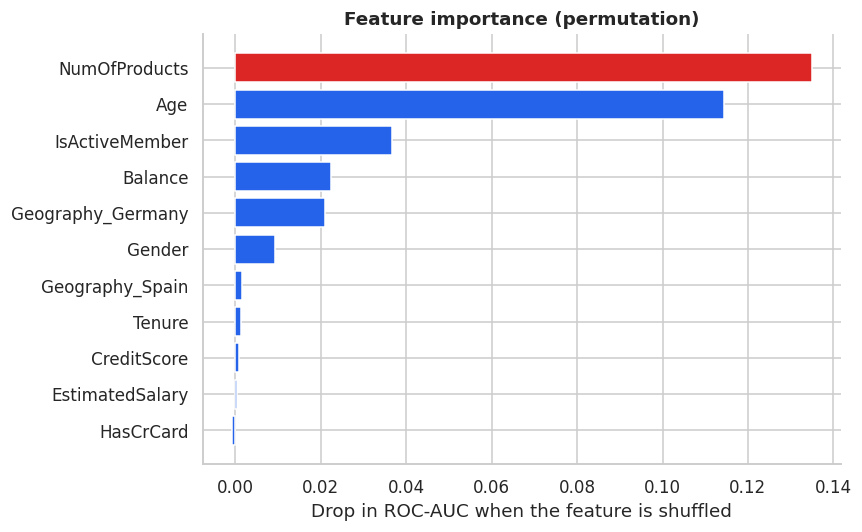

Top 3 drivers: ['NumOfProducts', 'Age', 'IsActiveMember']


In [19]:
def perm_importance(mdl, Xs, yy, n_rep=5):
    rng = np.random.default_rng(SEED)
    base = roc_auc_score(yy, mdl.predict(Xs, verbose=0).ravel())
    out = {}
    for j, c in enumerate(feature_names):
        drops = []
        for _ in range(n_rep):
            Xp = Xs.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
            drops.append(base - roc_auc_score(yy, mdl.predict(Xp, verbose=0).ravel()))
        out[c] = np.mean(drops)
    return pd.Series(out).sort_values()

imp = perm_importance(model, X_test_s, y_test)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=[C_CHURN if v == imp.max() else C_STAY for v in imp.values])
ax.set_xlabel('Drop in ROC-AUC when the feature is shuffled'); ax.set_title('Feature importance (permutation)')
plt.tight_layout(); plt.show()
top3 = list(imp.sort_values(ascending=False).index[:3])
print('Top 3 drivers:', top3)

<a id="s13"></a>
## 13. Predictions for New Customers
`predict_churn()` takes raw customer details (as a bank officer would enter them), applies the same preprocessing and scaling as in training, and returns the churn probability, risk band and decision.

**Risk bands** (derived from the tuned threshold): *High* = probability at or above the threshold; *Medium* = between half the threshold and the threshold; *Low* = below that.

In [20]:
def risk_band(p):
    return 'High' if p >= THR else ('Medium' if p >= THR / 2 else 'Low')

def predict_churn(credit_score, geography, gender, age, tenure, balance, num_products, has_card, is_active, salary):
    row = pd.DataFrame([{'CreditScore': credit_score, 'Gender': 1 if gender == 'Male' else 0, 'Age': age, 'Tenure': tenure,
                         'Balance': balance, 'NumOfProducts': num_products, 'HasCrCard': int(has_card),
                         'IsActiveMember': int(is_active), 'EstimatedSalary': salary,
                         'Geography_Germany': int(geography == 'Germany'), 'Geography_Spain': int(geography == 'Spain')}])[feature_names]
    return float(model.predict(scaler.transform(row), verbose=0)[0, 0])

examples = pd.DataFrame([
    ('Customer A', 600, 'Germany', 'Female', 52, 3, 120000, 1, 1, 0, 90000),
    ('Customer B', 750, 'France',  'Male',   30, 7,  20000, 2, 1, 1, 60000),
    ('Customer C', 680, 'Spain',   'Male',   45, 4,  60000, 1, 0, 1, 70000)],
    columns=['Customer', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'Products', 'HasCard', 'Active', 'Salary'])
examples['Churn probability'] = [predict_churn(*r[1:]) for r in examples.itertuples(index=False)]
examples['Risk band'] = examples['Churn probability'].map(risk_band)
examples['Decision'] = np.where(examples['Churn probability'] >= THR, 'Likely to LEAVE', 'Likely to STAY')
display(examples.style.format({'Churn probability': '{:.1%}', 'Balance': '{:,.0f}', 'Salary': '{:,.0f}'}).hide(axis='index'))

Customer,CreditScore,Geography,Gender,Age,Tenure,Balance,Products,HasCard,Active,Salary,Churn probability,Risk band,Decision
Customer A,600,Germany,Female,52,3,"120,000",1,1,0,"90,000",91.5%,High,Likely to LEAVE
Customer B,750,France,Male,30,7,"20,000",2,1,1,"60,000",4.8%,Low,Likely to STAY
Customer C,680,Spain,Male,45,4,"60,000",1,0,1,"70,000",51.7%,Medium,Likely to STAY


<a id="s14"></a>
## 14. Dashboard

In [21]:
# Scoring the test customers: used by the dashboard
scored = df.loc[X_test.index, ['Geography', 'Gender', 'Age', 'CreditScore', 'Balance', 'NumOfProducts', 'IsActiveMember']].copy()
scored['ChurnProbability'] = p_test
scored['Actual'] = y_test.values
scored['RiskBand'] = scored['ChurnProbability'].map(risk_band)

band_tbl = (scored.groupby('RiskBand').agg(Customers=('Actual', 'size'), ActualChurnRate=('Actual', 'mean'))
            .reindex(['Low', 'Medium', 'High']))

scored['Decile'] = pd.qcut(scored['ChurnProbability'].rank(method='first', ascending=False), 10, labels=range(1, 11))
lift = scored.groupby('Decile', observed=True)['Actual'].mean()
top20_capture = scored.loc[scored['Decile'].astype(int) <= 2, 'Actual'].sum() / scored['Actual'].sum()

def kpi(label, value, color='#0f172a'):
    return ('<div style="flex:1;min-width:120px;background:#f8fafc;border:1px solid #e2e8f0;border-radius:10px;padding:12px 8px;text-align:center">'
            f'<div style="font-size:12px;color:#64748b">{label}</div><div style="font-size:24px;font-weight:700;color:{color}">{value}</div></div>')

cards = ''.join([kpi('Customers', f'{len(df):,}'), kpi('Overall churn rate', f'{df.Exited.mean():.1%}', C_CHURN),
                 kpi('Accuracy', f'{acc:.1%}'), kpi('Precision', f'{prec:.1%}'), kpi('Recall', f'{rec_:.1%}'),
                 kpi('F1-score', f'{f1:.1%}'), kpi('ROC-AUC', f'{auc:.3f}'), kpi('Top 20% risk captures', f'{top20_capture:.0%} of churners', C_STAY)])
display(HTML('<h2 style="margin:4px 0 10px 0">Customer Churn Dashboard</h2>'
             f'<div style="display:flex;gap:10px;flex-wrap:wrap">{cards}</div>'))

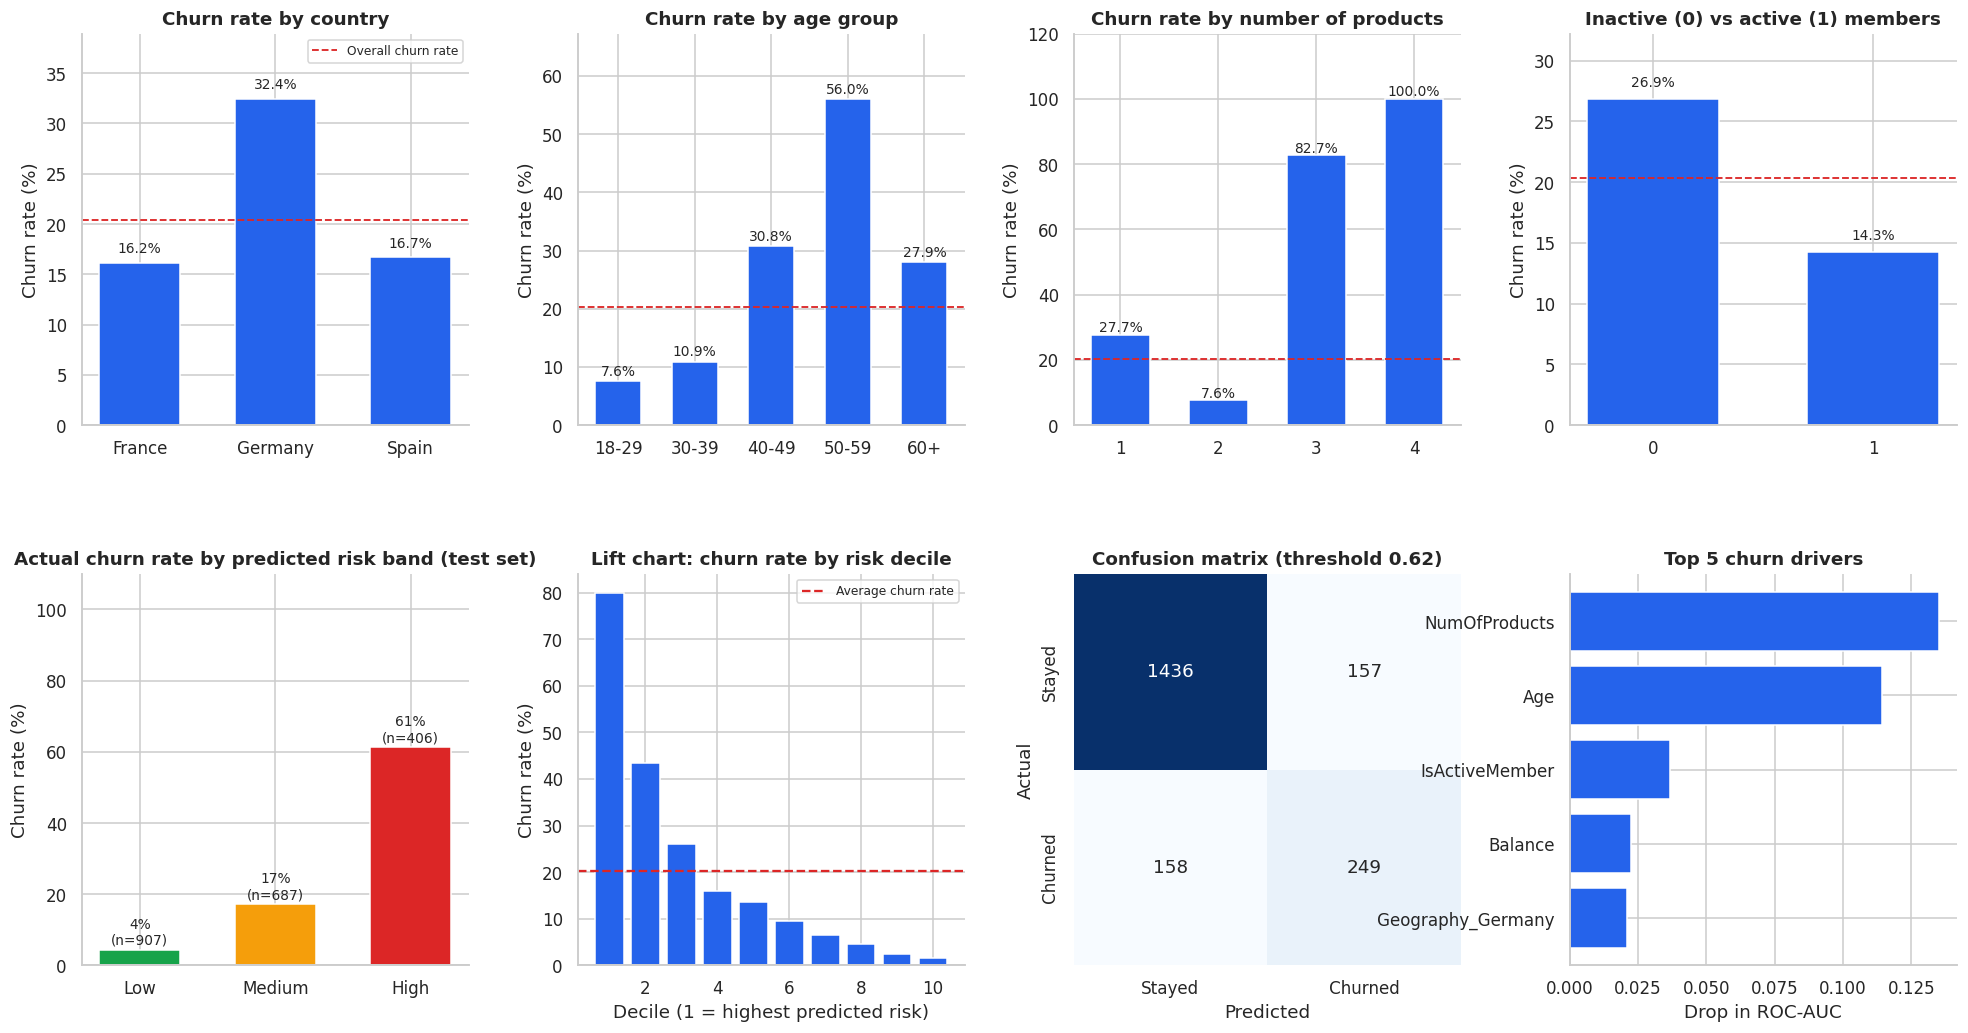

In [22]:
fig = plt.figure(figsize=(22, 11)); gs = GridSpec(2, 4, figure=fig, hspace=.38, wspace=.28)
ax = [fig.add_subplot(gs[i, j]) for i in range(2) for j in range(4)]

rate_bar(ax[0], 'Geography', 'Churn rate by country'); ax[0].legend(fontsize=8)
rate_bar(ax[1], 'AgeGroup', 'Churn rate by age group')
rate_bar(ax[2], 'NumOfProducts', 'Churn rate by number of products')
rate_bar(ax[3], 'IsActiveMember', 'Inactive (0) vs active (1) members')

bt = band_tbl.copy(); colors = ['#16a34a', '#f59e0b', C_CHURN]
b = ax[4].bar(bt.index, bt['ActualChurnRate'] * 100, color=colors, width=.6)
for bar, (n, r) in zip(b, zip(bt['Customers'], bt['ActualChurnRate'])):
    ax[4].text(bar.get_x() + bar.get_width() / 2, r * 100 + 1.5, f'{r:.0%}\n(n={n:,})', ha='center', fontsize=9)
ax[4].set_title('Actual churn rate by predicted risk band (test set)'); ax[4].set_ylabel('Churn rate (%)'); ax[4].set_ylim(0, 110)

ax[5].bar(lift.index.astype(int), lift.values * 100, color=C_STAY)
ax[5].axhline(y_test.mean() * 100, color=C_CHURN, ls='--', label='Average churn rate')
ax[5].set_title('Lift chart: churn rate by risk decile'); ax[5].set_xlabel('Decile (1 = highest predicted risk)'); ax[5].set_ylabel('Churn rate (%)'); ax[5].legend(fontsize=8)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[6], xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
ax[6].set_title(f'Confusion matrix (threshold {THR:.2f})'); ax[6].set_xlabel('Predicted'); ax[6].set_ylabel('Actual')

top5 = imp.sort_values().tail(5)
ax[7].barh(top5.index, top5.values, color=C_STAY); ax[7].set_title('Top 5 churn drivers'); ax[7].set_xlabel('Drop in ROC-AUC')
plt.show()

In [23]:
display(HTML('<h3>Top 10 highest-risk customers (test set)</h3>'))
top10 = scored.sort_values('ChurnProbability', ascending=False).head(10).drop(columns=['Decile']).reset_index(drop=True)
display(top10.style.format({'ChurnProbability': '{:.1%}', 'Balance': '{:,.0f}'}).hide(axis='index'))

Geography,Gender,Age,CreditScore,Balance,NumOfProducts,IsActiveMember,ChurnProbability,Actual,RiskBand
France,Female,61,611,"131,584",4,1,100.0%,1,High
Germany,Male,58,738,"133,745",4,0,100.0%,1,High
France,Male,48,642,"118,317",4,0,100.0%,1,High
Germany,Male,49,575,"121,205",4,1,99.9%,1,High
Germany,Male,46,727,"115,248",4,0,99.9%,1,High
Germany,Male,43,568,"87,613",4,1,99.9%,1,High
Germany,Female,37,584,"134,172",4,1,99.9%,1,High
Spain,Male,30,596,"121,346",4,0,99.9%,1,High
Germany,Female,41,847,"101,544",4,0,99.9%,1,High
France,Male,50,792,0,4,1,99.8%,1,High


<a id="s15"></a>
## 15. User Interface (interactive churn predictor)
Enter a customer's details and click **Predict churn**. The tool returns the churn probability, the risk band and a suggested action. *(Interactive widgets: run this cell in Jupyter, VS Code or Colab; requires `ipywidgets`.)*

In [24]:
import ipywidgets as widgets
from IPython.display import clear_output

S = {'description_width': '130px'}; L = widgets.Layout(width='440px')
w_cs   = widgets.IntSlider(value=650, min=300, max=900, description='Credit score', style=S, layout=L)
w_geo  = widgets.Dropdown(options=['France', 'Germany', 'Spain'], description='Country', style=S, layout=L)
w_gen  = widgets.ToggleButtons(options=['Female', 'Male'], description='Gender', style=S)
w_age  = widgets.IntSlider(value=40, min=18, max=92, description='Age', style=S, layout=L)
w_ten  = widgets.IntSlider(value=5, min=0, max=10, description='Tenure (years)', style=S, layout=L)
w_bal  = widgets.BoundedFloatText(value=75000.0, min=0, max=500000, step=1000, description='Balance', style=S, layout=L)
w_prod = widgets.IntSlider(value=1, min=1, max=4, description='No. of products', style=S, layout=L)
w_card = widgets.Checkbox(value=True, description='Has credit card', indent=False)
w_act  = widgets.Checkbox(value=True, description='Is active member', indent=False)
w_sal  = widgets.BoundedFloatText(value=100000.0, min=0, max=500000, step=1000, description='Est. salary', style=S, layout=L)
w_btn  = widgets.Button(description='Predict churn', button_style='primary', icon='search')
w_out  = widgets.Output()

ACTIONS = {'High': 'Priority retention call and a personalised offer (better rate, loyalty reward).',
           'Medium': 'Add to a watch-list; send engagement campaigns and check satisfaction.',
           'Low': 'No action needed; continue normal service.'}
BAND_COLOR = {'High': '#dc2626', 'Medium': '#f59e0b', 'Low': '#16a34a'}

def on_predict(_):
    with w_out:
        clear_output()
        p = predict_churn(w_cs.value, w_geo.value, w_gen.value, w_age.value, w_ten.value, w_bal.value,
                          w_prod.value, w_card.value, w_act.value, w_sal.value)
        band = risk_band(p); col = BAND_COLOR[band]
        display(HTML(
            f'<div style="max-width:440px;border:2px solid {col};border-radius:12px;padding:14px">'
            f'<div style="font-size:13px;color:#64748b">Churn probability</div>'
            f'<div style="font-size:34px;font-weight:700;color:{col}">{p:.1%}</div>'
            f'<div style="background:#e2e8f0;border-radius:6px;height:12px;margin:6px 0"><div style="width:{p*100:.0f}%;background:{col};height:12px;border-radius:6px"></div></div>'
            f'<div style="font-size:16px;font-weight:600;color:{col}">{band.upper()} RISK: ' + ('likely to LEAVE' if p >= THR else 'likely to STAY') + '</div>'
            f'<div style="font-size:13px;margin-top:6px">Suggested action: {ACTIONS[band]}</div></div>'))
w_btn.on_click(on_predict)

display(widgets.VBox([widgets.HTML('<h3>Bank Customer Churn Predictor</h3>'),
                      w_cs, w_geo, w_gen, w_age, w_ten, w_bal, w_prod, w_card, w_act, w_sal, w_btn, w_out]))
on_predict(None)

<a id="s16"></a>
## 16. Conclusion and Recommendations

In [25]:
hi = band_tbl.loc['High']; lo = band_tbl.loc['Low']
display(Markdown(f"""### Executive summary
- **Objective:** predict which bank customers will churn so the bank can intervene early.
- **Model:** ANN (11 → 32 → 16 → 1, ReLU, dropout, sigmoid) trained with class weights and early stopping; decision threshold tuned on a separate validation set.
- **Result on unseen test data:** ROC-AUC **{auc:.3f}**, accuracy **{acc:.1%}**, precision **{prec:.1%}**, recall **{rec_:.1%}**, F1 **{f1:.1%}**, compared with a baseline Logistic Regression F1 of {res_lr['F1-score']:.1%} and ROC-AUC of {res_lr['ROC-AUC']:.3f}.
- **Targeting power:** contacting only the top 20% highest-risk customers reaches **{top20_capture:.0%} of all churners**. Customers in the model's High band churn at **{hi['ActualChurnRate']:.0%}**, versus **{lo['ActualChurnRate']:.0%}** in the Low band.

### What drives churn
- **Age:** customers aged 40+ churn at {ins['age40']:.1%} versus {ins['age_u40']:.1%} for younger customers.
- **Engagement:** inactive members churn at {ins['inactive']:.1%} versus {ins['active']:.1%} for active members.
- **Location:** Germany churns at {ins['germany']:.1%} (France {ins['france']:.1%}, Spain {ins['spain']:.1%}).
- **Product holding:** 3 to 4 products churn at {ins['p34']:.1%}, while 2 products is the healthiest at {ins['p2']:.1%}.
- The model's most important features are: **{', '.join(top3)}**.

### Recommendations for the bank
1. **Prioritise the High-risk band** for personal retention calls and tailored offers; use the dashboard list or the UI to score customers.
2. **Re-activate inactive members** with engagement campaigns (usage rewards, reminders), since inactivity is a strong early warning.
3. **Investigate the German market** (pricing, service quality, competition) because its churn rate is far above the other countries.
4. **Review the 3 to 4 product bundles:** customers with many products churn heavily, which may point to a product or fee problem.
5. **Build loyalty programmes for customers aged 40+**, the highest-churn age segment.

### Limitations and future work
- The model finds about {rec_:.0%} of churners; the rest are missed. The threshold can be lowered if the cost of losing a customer is higher than the cost of a retention offer.
- The data is a single snapshot with no time dimension, transaction history or complaint data; adding these would likely improve accuracy.
- Next steps: compare with tree-based models (Random Forest, XGBoost), try SMOTE or cost-sensitive learning, add model explanations (SHAP), and monitor the model over time."""))

### Executive summary
- **Objective:** predict which bank customers will churn so the bank can intervene early.
- **Model:** ANN (11 → 32 → 16 → 1, ReLU, dropout, sigmoid) trained with class weights and early stopping; decision threshold tuned on a separate validation set.
- **Result on unseen test data:** ROC-AUC **0.856**, accuracy **84.2%**, precision **61.3%**, recall **61.2%**, F1 **61.3%**, compared with a baseline Logistic Regression F1 of 49.7% and ROC-AUC of 0.778.
- **Targeting power:** contacting only the top 20% highest-risk customers reaches **61% of all churners**. Customers in the model's High band churn at **61%**, versus **4%** in the Low band.

### What drives churn
- **Age:** customers aged 40+ churn at 35.9% versus 10.0% for younger customers.
- **Engagement:** inactive members churn at 26.9% versus 14.3% for active members.
- **Location:** Germany churns at 32.4% (France 16.2%, Spain 16.7%).
- **Product holding:** 3 to 4 products churn at 85.9%, while 2 products is the healthiest at 7.6%.
- The model's most important features are: **NumOfProducts, Age, IsActiveMember**.

### Recommendations for the bank
1. **Prioritise the High-risk band** for personal retention calls and tailored offers; use the dashboard list or the UI to score customers.
2. **Re-activate inactive members** with engagement campaigns (usage rewards, reminders), since inactivity is a strong early warning.
3. **Investigate the German market** (pricing, service quality, competition) because its churn rate is far above the other countries.
4. **Review the 3 to 4 product bundles:** customers with many products churn heavily, which may point to a product or fee problem.
5. **Build loyalty programmes for customers aged 40+**, the highest-churn age segment.

### Limitations and future work
- The model finds about 61% of churners; the rest are missed. The threshold can be lowered if the cost of losing a customer is higher than the cost of a retention offer.
- The data is a single snapshot with no time dimension, transaction history or complaint data; adding these would likely improve accuracy.
- Next steps: compare with tree-based models (Random Forest, XGBoost), try SMOTE or cost-sensitive learning, add model explanations (SHAP), and monitor the model over time.

### Save model artifacts

In [26]:
import joblib
model.save('churn_ann_model.keras')
joblib.dump(scaler, 'churn_scaler.joblib')
with open('churn_config.json', 'w') as f:
    json.dump({'threshold': THR, 'features': feature_names, 'seed': SEED}, f, indent=2)
scored.drop(columns=['Decile']).to_csv('churn_test_predictions.csv', index=False)
print('Saved: churn_ann_model.keras, churn_scaler.joblib, churn_config.json, churn_test_predictions.csv')

Saved: churn_ann_model.keras, churn_scaler.joblib, churn_config.json, churn_test_predictions.csv
